
## Summary: T1X vs RDB7 Comparison Tools

This is a complete toolkit to compare transition states between the two datasets!

### Key Findings:
- **9,753 common reactions** between T1X and RDB7 (matched by SMILES string)
- **T1X**: Per-sample `ts_idx` marks which image is the TS in a multi-image NEB pathway (~10 images)
- **RDB7**: Fixed 3-image representation (Reactant, TS, Product) with no explicit TS index

### Available Functions:

1. **`compare_reaction_by_smiles(smiles_string, visualize=True)`**
   - Find a reaction in both datasets by its SMILES string
   - Optionally open 3D ASE GUI windows for comparison
   - Returns ASE Atoms objects for further analysis

2. **`get_ts_from_t1x(sample)` and `get_ts_from_rdb7(sample)`**
   - Extract transition state coordinates from either dataset

3. **`visualize_reaction_pathway(t1x_sample)`**
   - Plot a 2D projection of the full reaction pathway
   - Shows all NEB images with TS highlighted

4. **`atoms_from_coords(coords, atom_types)`**
   - Convert coordinate arrays to ASE Atoms objects

### Quick Start Examples:

```python
# List first 10 common reactions
print(list(common_smiles)[:10])

# Compare a specific reaction with 3D visualization
result = compare_reaction_by_smiles(
    smiles_string=list(common_smiles)[0],
    visualize=True
)

# Visualize T1X reaction pathway
visualize_reaction_pathway(t1x_sample)
```

### ASE GUI Controls:
- **Rotate**: Click + drag
- **Zoom**: Scroll wheel
- **Pan**: Shift + click + drag
- **Bond info**: Hover over bonds
- **Export**: Use menu options to save as XYZ, PDB, etc.


In [1]:
import pickle
import torch
from ase import Atoms
from ase.gui.gui import GUI
import numpy as np

In [2]:
with open('T1X/data_inr.pkl', 'rb') as f:
    t1x_data = pickle.load(f)

with open('RDB7/processed_data/data.pkl', 'rb') as f:
    rdb7_data = pickle.load(f)


# Display types and basic info
type(t1x_data), type(rdb7_data), len(t1x_data) if hasattr(t1x_data, '__len__') else None, len(rdb7_data) if hasattr(rdb7_data, '__len__') else None


(list, list, 9847, 11926)

In [3]:

# ============================================================================
# COMPARISON: T1X vs RDB7 Datasets
# ============================================================================

print("=" * 80)
print("DATASET COMPARISON: T1X vs RDB7")
print("=" * 80)

# Dataset sizes
print(f"\nDataset Sizes:")
print(f"  T1X:  {len(t1x_data)} samples")
print(f"  RDB7: {len(rdb7_data)} samples")

# Sample a record from each
t1x_sample = t1x_data[1]
rdb7_sample = rdb7_data[1]

print(f"\n{'-' * 80}")
print("KEY STRUCTURAL DIFFERENCES:")
print(f"{'-' * 80}")

# Check for critical attributes
t1x_keys = set(t1x_sample.keys()) if hasattr(t1x_sample, 'keys') else set()
rdb7_keys = set(rdb7_sample.keys()) if hasattr(rdb7_sample, 'keys') else set()

print(f"\nT1X attributes:  {sorted(t1x_keys)}")
print(f"RDB7 attributes: {sorted(rdb7_keys)}")

# Unique to each
only_t1x = t1x_keys - rdb7_keys
only_rdb7 = rdb7_keys - t1x_keys

if only_t1x:
    print(f"\n✓ UNIQUE TO T1X: {sorted(only_t1x)}")
if only_rdb7:
    print(f"\n✓ UNIQUE TO RDB7: {sorted(only_rdb7)}")

common = t1x_keys & rdb7_keys
if common:
    print(f"\n✓ COMMON ATTRIBUTES: {sorted(common)}")

print(f"\n{'-' * 80}")
print("DETAILED FIELD COMPARISON:")
print(f"{'-' * 80}")

# Critical difference 1: Transition State (TS) handling
print(f"\n1. TRANSITION STATE (TS) HANDLING:")
print(f"   T1X ts_idx: {t1x_sample.ts_idx} (scalar per-sample TS index)")
if hasattr(rdb7_sample, 'ts_idx'):
    print(f"   RDB7 ts_idx: {rdb7_sample.ts_idx}")
else:
    print(f"   RDB7 ts_idx: NOT PRESENT (no per-sample TS tracking)")

# Critical difference 2: Coordinates/Positions
print(f"\n2. COORDINATES/POSITIONS:")
if hasattr(t1x_sample, 'pos_N_3_I'):
    pos_shape = t1x_sample.pos_N_3_I.shape
    print(f"   T1X pos_N_3_I shape: {pos_shape}")
    print(f"      → (atoms={pos_shape[0]}, xyz={pos_shape[1]}, images={pos_shape[2]})")
    print(f"      → Contains {pos_shape[2]} images of the reaction path (NEB-like)")
else:
    print(f"   T1X pos_N_3_I: NOT PRESENT")

if hasattr(rdb7_sample, 'pos'):
    pos_shape = rdb7_sample.pos.shape
    print(f"   RDB7 pos shape: {pos_shape}")
    print(f"      → (atoms={pos_shape[0]}, xyz={pos_shape[1]}, images={pos_shape[2] if len(pos_shape) > 2 else 'N/A'})")
else:
    print(f"   RDB7 pos: NOT PRESENT")

# Critical difference 3: Feature dimensions
print(f"\n3. FEATURE DIMENSIONS:")
if hasattr(t1x_sample, 'r_feat_N_Z'):
    print(f"   T1X r_feat_N_Z shape: {t1x_sample.r_feat_N_Z.shape}")
else:
    print(f"   T1X r_feat_N_Z: NOT PRESENT")

if hasattr(rdb7_sample, 'r_feat'):
    print(f"   RDB7 r_feat shape: {rdb7_sample.r_feat.shape}")
else:
    print(f"   RDB7 r_feat: NOT PRESENT")

# Critical difference 4: Indices and mappings
print(f"\n4. INDICES & MAPPINGS:")
print(f"   T1X has:")
if hasattr(t1x_sample, 'r_index_to_mapnum'):
    print(f"      - r_index_to_mapnum (reactant atom → mapping number)")
if hasattr(t1x_sample, 'mapnum_to_r_index'):
    print(f"      - mapnum_to_r_index (mapping number → reactant atom)")
if hasattr(t1x_sample, 'mapnum_to_p_index'):
    print(f"      - mapnum_to_p_index (mapping number → product atom)")

print(f"\n   RDB7 has:")
if hasattr(rdb7_sample, 'rxn_index'):
    print(f"      - rxn_index: {rdb7_sample.rxn_index}")
if hasattr(rdb7_sample, 'augmented'):
    print(f"      - augmented: {rdb7_sample.augmented} (data augmentation flag)")


DATASET COMPARISON: T1X vs RDB7

Dataset Sizes:
  T1X:  9847 samples
  RDB7: 11926 samples

--------------------------------------------------------------------------------
KEY STRUCTURAL DIFFERENCES:
--------------------------------------------------------------------------------

T1X attributes:  ['atom_type_N', 'edge_index', 'edge_type', 'mapnum_to_p_index', 'mapnum_to_r_index', 'p_edge_index', 'p_feat_N_Z', 'p_index_to_mapnum', 'pos_N_3_I', 'r_edge_index', 'r_feat_N_Z', 'r_index_to_mapnum', 'rdmol', 'rxn_idx', 'smiles', 'ts_idx']
RDB7 attributes: ['atom_type', 'augmented', 'edge_index', 'edge_type', 'mapnum_to_p_index', 'mapnum_to_r_index', 'p_chiraltype', 'p_edge_index', 'p_feat', 'p_index_to_mapnum', 'pos', 'r_chiraltype', 'r_edge_index', 'r_feat', 'r_index_to_mapnum', 'rdmol', 'rxn_index', 'smiles']

✓ UNIQUE TO T1X: ['atom_type_N', 'p_feat_N_Z', 'pos_N_3_I', 'r_feat_N_Z', 'rxn_idx', 'ts_idx']

✓ UNIQUE TO RDB7: ['atom_type', 'augmented', 'p_chiraltype', 'p_feat', 'pos', 'r_chir

In [4]:

import pandas as pd

# ============================================================================
# SUMMARY TABLE
# ============================================================================

comparison_data = {
    'Feature': [
        'Transition State Index',
        'Coordinates Field',
        'Coordinate Shape',
        'Reaction Path',
        'Feature Field (Reactant)',
        'Feature Field (Product)',
        'Augmentation Flag',
        'Reaction ID',
        'Atom Type Field',
    ],
    'T1X': [
        'ts_idx (scalar per-sample)',
        'pos_N_3_I',
        '(N_atoms, 3, N_images)',
        'Multi-image NEB path (typically 10 images)',
        'r_feat_N_Z',
        'p_feat_N_Z',
        'Not present',
        'rxn_idx (string ID)',
        'atom_type_N',
    ],
    'RDB7': [
        'Not present',
        'pos',
        '(N_atoms, 3, N_states) — typically 3 states (R, TS, P)',
        'Usually 3 images: reactant, transition state, product',
        'r_feat',
        'p_feat',
        'augmented (bool)',
        'rxn_index (integer)',
        'atom_type',
    ]
}

df_comparison = pd.DataFrame(comparison_data)
print("\n" + "=" * 120)
print("SIDE-BY-SIDE COMPARISON TABLE:")
print("=" * 120)
print(df_comparison.to_string(index=False))
print("=" * 120)

print("\n" + "▶ KEY TAKEAWAYS:" + "\n")
print("  1. T1X → Per-sample TS index (ts_idx) selects which image is the transition state")
print("       RDB7 → No explicit per-sample TS index; the structure is typically (R, TS, P)")
print()
print("  2. T1X → Multi-image NEB pathway (e.g., 10 images)")
print("       RDB7 → Sparse 3-image representation (R, TS, P)")
print()
print("  3. T1X → Features: r_feat_N_Z, p_feat_N_Z (per-atom feature matrices, shape [N, Z])")
print("       RDB7 → Features: r_feat, p_feat (different dimensions, likely shape [N, 27])")
print()
print("  4. T1X → Reaction identified by rxn_idx (string, e.g., 'rxn2092')")
print("       RDB7 → Reaction identified by rxn_index (integer) + augmented flag")
print()
print("  5. T1X → Coordinates stored as (N, 3, I) — atoms × xyz × images")
print("       RDB7 → Coordinates stored as (N, 3, I) — same shape, but typically I=3")



SIDE-BY-SIDE COMPARISON TABLE:
                 Feature                                        T1X                                                   RDB7
  Transition State Index                 ts_idx (scalar per-sample)                                            Not present
       Coordinates Field                                  pos_N_3_I                                                    pos
        Coordinate Shape                     (N_atoms, 3, N_images) (N_atoms, 3, N_states) — typically 3 states (R, TS, P)
           Reaction Path Multi-image NEB path (typically 10 images)  Usually 3 images: reactant, transition state, product
Feature Field (Reactant)                                 r_feat_N_Z                                                 r_feat
 Feature Field (Product)                                 p_feat_N_Z                                                 p_feat
       Augmentation Flag                                Not present                                       a

In [5]:

# ============================================================================
# STEP 1: Build a lookup table of SMILES → data for quick matching
# ============================================================================

from collections import defaultdict

# Create SMILES lookup for both datasets
t1x_by_smiles = {}
for idx, sample in enumerate(t1x_data):
    smiles = sample.smiles
    if smiles not in t1x_by_smiles:
        t1x_by_smiles[smiles] = []
    t1x_by_smiles[smiles].append(idx)

rdb7_by_smiles = {}
for idx, sample in enumerate(rdb7_data):
    smiles = sample.smiles
    if smiles not in rdb7_by_smiles:
        rdb7_by_smiles[smiles] = []
    rdb7_by_smiles[smiles].append(idx)

# Find common SMILES
common_smiles = set(t1x_by_smiles.keys()) & set(rdb7_by_smiles.keys())

print(f"Total unique SMILES in T1X:  {len(t1x_by_smiles)}")
print(f"Total unique SMILES in RDB7: {len(rdb7_by_smiles)}")
print(f"Common reactions (by SMILES): {len(common_smiles)}")

# Show a few examples
print(f"\nFirst 5 common reactions:")
for i, smiles in enumerate(list(common_smiles)[:5]):
    print(f"  {i+1}. T1X indices: {t1x_by_smiles[smiles]}, RDB7 indices: {rdb7_by_smiles[smiles]}")


Total unique SMILES in T1X:  9847
Total unique SMILES in RDB7: 11926
Common reactions (by SMILES): 9753

First 5 common reactions:
  1. T1X indices: [5840], RDB7 indices: [8074]
  2. T1X indices: [8445], RDB7 indices: [9538]
  3. T1X indices: [6699], RDB7 indices: [7110]
  4. T1X indices: [3137], RDB7 indices: [925]
  5. T1X indices: [8287], RDB7 indices: [4466]


In [6]:
# ============================================================================
# STEP 2: Helper functions to extract and visualize transition states
# ============================================================================

def get_ts_from_t1x(data_sample):
    """
    Extract transition state coordinates from T1X sample.
    T1X has shape (N_atoms, 3, N_images) and ts_idx tells us which image is the TS.
    """
    ts_idx = data_sample.ts_idx
    # Convert to int if tensor
    try:
        if hasattr(ts_idx, 'item'):  # torch tensor
            ts_idx = int(ts_idx.item())
        else:
            ts_idx = int(ts_idx)
    except:
        ts_idx = int(ts_idx)
    
    pos_N_3_I = data_sample.pos_N_3_I  # shape: (N_atoms, 3, N_images)
    ts_coords = pos_N_3_I[:, :, ts_idx]  # shape: (N_atoms, 3)
    
    return ts_coords, ts_idx

def get_ts_from_rdb7(data_sample):
    """
    Extract transition state coordinates from RDB7 sample.
    RDB7 typically has shape (N_atoms, 3, 3) where index 1 is the TS.
    """
    pos = data_sample.pos  # shape: (N_atoms, 3, 3) or (N_atoms, 3)
    ts_idx = 1
    ts_coords = pos[:, ts_idx, :]
    
    return ts_coords, ts_idx

def atoms_from_coords(coords_N_3, atom_types_N, name="molecule"):
    """
    Create an ASE Atoms object from coordinates and atom types.
    
    Args:
        coords_N_3: (N, 3) numpy array of coordinates
        atom_types_N: (N,) array of atomic numbers or symbol strings
        name: name for the atoms object
    
    Returns:
        ASE Atoms object
    """
    import numpy as np
    
    # Convert coords to numpy if it's a tensor
    if hasattr(coords_N_3, 'cpu'):  # torch tensor
        coords_N_3 = coords_N_3.cpu().numpy()
    else:
        coords_N_3 = np.array(coords_N_3)
    
    # Convert atom_types to numpy if needed
    if hasattr(atom_types_N, 'cpu'):  # torch tensor
        atom_types_N = atom_types_N.cpu().numpy()
    else:
        atom_types_N = np.array(atom_types_N)
    
    # Create Atoms object
    atoms = Atoms(numbers=atom_types_N, positions=coords_N_3)
    return atoms

def kabsch_align(P, Q):
    """
    Align Q onto P using the Kabsch algorithm.
    Both P and Q are (N,3) numpy arrays. Returns rotated Q (aligned to P).
    """
    import numpy as _np

    P = _np.asarray(P)
    Q = _np.asarray(Q)
    if P.shape != Q.shape:
        raise ValueError("P and Q must have the same shape for Kabsch alignment")

    # Center
    P_centroid = P.mean(axis=0)
    Q_centroid = Q.mean(axis=0)
    P_centered = P - P_centroid
    Q_centered = Q - Q_centroid

    # Covariance
    C = Q_centered.T @ P_centered
    V, S, Wt = _np.linalg.svd(C)
    d = _np.sign(_np.linalg.det(V @ Wt))
    D = _np.diag([1.0, 1.0, d])
    U = V @ D @ Wt

    Q_rot = (Q_centered @ U)
    # Translate back to P centroid
    Q_aligned = Q_rot + P_centroid
    return Q_aligned

def visualize_two_structures(atoms1, atoms2, title1="Structure 1", title2="Structure 2", backend='matplotlib'):
    """
    Visualize two structures using plotly, nglview, matplotlib, or ase.
    
    Parameters:
    -----------
    atoms1, atoms2 : ASE Atoms objects
    title1, title2 : str
    backend : str
        'plotly': Interactive 3D scatter (side-by-side in HTML)
        'nglview': Molecular viewer with proper bonds (interactive in Jupyter)
        'matplotlib': Static 3D plots side-by-side
        'ase': ASE GUI (if available)
    
    Returns: None, None
    """
    
    # ===== Plotly backend =====
    if backend == 'plotly':
        try:
            import plotly.graph_objects as go
            import numpy as _np
            
            coords1 = atoms1.get_positions()
            coords2 = atoms2.get_positions()
            
            fig = go.Figure()
            
            # Add T1X
            fig.add_trace(go.Scatter3d(
                x=coords1[:, 0], y=coords1[:, 1], z=coords1[:, 2],
                mode='markers',
                name=title1,
                marker=dict(size=5, color='red'),
                text=[f"Atom {i}" for i in range(len(coords1))],
                hoverinfo='text'
            ))
            
            # Add RDB7
            fig.add_trace(go.Scatter3d(
                x=coords2[:, 0], y=coords2[:, 1], z=coords2[:, 2],
                mode='markers',
                name=title2,
                marker=dict(size=5, color='blue'),
                text=[f"Atom {i}" for i in range(len(coords2))],
                hoverinfo='text'
            ))
            
            fig.update_layout(
                title=f"{title1} vs {title2}",
                scene=dict(aspectmode='data'),
                hovermode='closest'
            )
            fig.show()
            return None, None
        except Exception as e:
            print("Plotly failed:", e)
            backend = 'matplotlib'  # Fall back

    # ===== nglview backend =====
    if backend == 'nglview':
        try:
            import nglview as nv
            
            # nglview works best with structure files; convert atoms to view
            view1 = nv.show_ase(atoms1)
            view1.add_representation('ball+stick')
            print(f"Showing {title1} in nglview...")
            
            view2 = nv.show_ase(atoms2)
            view2.add_representation('ball+stick')
            print(f"Showing {title2} in nglview...")
            
            return view1, view2
        except Exception as e:
            print("nglview failed:", e)
            backend = 'matplotlib'  # Fall back

    # ===== ASE backend =====
    if backend == 'ase':
        try:
            from ase.visualize import view
            print(f"Opening viewer for: {title1}")
            view(atoms1)
            print(f"Opening viewer for: {title2}")
            view(atoms2)
            return None, None
        except Exception as e:
            print("ASE viewer failed:", e)
            backend = 'matplotlib'  # Fall back

    # ===== Matplotlib fallback =====
    if backend == 'matplotlib':
        try:
            import matplotlib.pyplot as plt
            from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
            import numpy as _np

            coords1 = atoms1.get_positions()
            coords2 = atoms2.get_positions()

            fig = plt.figure(figsize=(10, 5))
            ax1 = fig.add_subplot(1, 2, 1, projection='3d')
            ax2 = fig.add_subplot(1, 2, 2, projection='3d')

            ax1.scatter(coords1[:, 0], coords1[:, 1], coords1[:, 2], s=60)
            ax2.scatter(coords2[:, 0], coords2[:, 1], coords2[:, 2], s=60)

            ax1.set_title(title1)
            ax2.set_title(title2)

            # Label a few atoms
            for i in range(min(6, len(coords1))):
                ax1.text(coords1[i, 0], coords1[i, 1], coords1[i, 2], str(i), fontsize=8)
            for i in range(min(6, len(coords2))):
                ax2.text(coords2[i, 0], coords2[i, 1], coords2[i, 2], str(i), fontsize=8)

            # Match axes limits for easier comparison
            all_coords = _np.vstack([coords1, coords2])
            mins = all_coords.min(axis=0)
            maxs = all_coords.max(axis=0)
            for ax in (ax1, ax2):
                ax.set_xlim(mins[0], maxs[0])
                ax.set_ylim(mins[1], maxs[1])
                ax.set_zlim(mins[2], maxs[2])

            plt.tight_layout()
            plt.show()
            return None, None
        except Exception as e:
            print("Matplotlib fallback failed:", e)
            return None, None

print("✓ Helper functions loaded successfully!")
print("  - get_ts_from_t1x(): Extract T1X transition state")
print("  - get_ts_from_rdb7(): Extract RDB7 transition state")
print("  - atoms_from_coords(): Create ASE Atoms object")
print("  - visualize_two_structures(): Open side-by-side comparison (plotly, nglview, matplotlib, or ase)")

✓ Helper functions loaded successfully!
  - get_ts_from_t1x(): Extract T1X transition state
  - get_ts_from_rdb7(): Extract RDB7 transition state
  - atoms_from_coords(): Create ASE Atoms object
  - visualize_two_structures(): Open side-by-side comparison (plotly, nglview, matplotlib, or ase)


In [17]:

# ============================================================================
# STEP 3: Pick a common reaction and compare transition states
# ============================================================================

# Pick the first common reaction as an example
example_smiles = list(common_smiles)[0]

# Get indices
t1x_idx = t1x_by_smiles[example_smiles][0]
rdb7_idx = rdb7_by_smiles[example_smiles][0]

# Load the samples
t1x_sample = t1x_data[t1x_idx]
rdb7_sample = rdb7_data[rdb7_idx]

print(f"=" * 100)
print(f"EXAMPLE REACTION COMPARISON")
print(f"=" * 100)
print(f"\nReaction SMILES:\n  {example_smiles}")
print(f"\nT1X sample index:  {t1x_idx}")
print(f"RDB7 sample index: {rdb7_idx}")

# Extract transition states
t1x_ts_coords, t1x_ts_idx = get_ts_from_t1x(t1x_sample)
rdb7_ts_coords, rdb7_ts_idx = get_ts_from_rdb7(rdb7_sample)

print(f"\nT1X TS Information:")
print(f"  - Image index (ts_idx): {t1x_ts_idx}")
print(f"  - Coordinates shape: {t1x_ts_coords.shape}")
print(f"  - Atom types shape: {t1x_sample.atom_type_N.shape}")

print(f"\nRDB7 TS Information:")
print(f"  - Image index: {rdb7_ts_idx} (always middle image)")
print(f"  - Coordinates shape: {rdb7_ts_coords.shape}")
print(f"  - Atom types shape: {rdb7_sample.atom_type.shape}")

# Create ASE Atoms objects
t1x_atoms = atoms_from_coords(t1x_ts_coords, t1x_sample.atom_type_N, f"T1X TS (img {t1x_ts_idx})")
rdb7_atoms = atoms_from_coords(rdb7_ts_coords, rdb7_sample.atom_type, f"RDB7 TS (img {rdb7_ts_idx})")

print(f"\n✓ ASE Atoms objects created for comparison")


EXAMPLE REACTION COMPARISON

Reaction SMILES:
  [C:1]([C:2]([C@@:3]([O:4][H:14])([C@@:5]([C:6]([H:16])([H:17])[H:18])([O:7][H:19])[H:15])[H:13])([H:11])[H:12])([H:8])([H:9])[H:10]>>[C:1]([C:2](/[C:3]([O:4][H:14])=[C:5](\[C:6]([H:16])([H:17])[H:18])[H:15])([H:11])[H:12])([H:8])([H:9])[H:10].[O:7]([H:13])[H:19]

T1X sample index:  5840
RDB7 sample index: 8074

T1X TS Information:
  - Image index (ts_idx): 6
  - Coordinates shape: torch.Size([19, 3])
  - Atom types shape: torch.Size([19])

RDB7 TS Information:
  - Image index: 1 (always middle image)
  - Coordinates shape: torch.Size([19, 3])
  - Atom types shape: torch.Size([19])

✓ ASE Atoms objects created for comparison


In [16]:

# ============================================================================
# STEP 4: Visualize the transition states with ASE GUI
# ============================================================================

# Uncomment the line below to open ASE GUI windows for 3D visualization
# Note: This opens interactive windows that allow rotation, zooming, etc.

# gui1, gui2 = visualize_two_structures(
#     t1x_atoms, 
#     rdb7_atoms,
#     title1=f"T1X TS (image {t1x_ts_idx})",
#     title2=f"RDB7 TS (image {rdb7_ts_idx})"
# )

print("\n" + "=" * 100)
print("TO VISUALIZE IN 3D:")
print("=" * 100)
print("\nUncomment the code cell below and run it to open interactive ASE GUI windows.")

# Calculate some basic geometry comparison
import numpy as np

def coords_to_np(coords):
    """Convert coordinates to numpy array."""
    if hasattr(coords, 'cpu'):
        return coords.cpu().numpy()
    return np.array(coords)

t1x_coords_np = coords_to_np(t1x_ts_coords)
rdb7_coords_np = coords_to_np(rdb7_ts_coords)

# Compute centroid
t1x_centroid = t1x_coords_np.mean(axis=0)
rdb7_centroid = rdb7_coords_np.mean(axis=0)

print(f"\nCentroid (center of mass):")
print(f"  T1X:  {t1x_centroid}")
print(f"  RDB7: {rdb7_centroid}")
print(f"  Difference: {np.linalg.norm(t1x_centroid - rdb7_centroid):.4f} Å")

# Center both structures
t1x_centered = t1x_coords_np - t1x_centroid
rdb7_centered = rdb7_coords_np - rdb7_centroid

# Compute pairwise distances (first 5 atoms)
print(f"\nPairwise distances (inter-atomic) - first 5 atoms:")
print(f"  T1X distances from atom 0:")
for i in range(1, min(6, len(t1x_centered))):
    dist = np.linalg.norm(t1x_centered[i] - t1x_centered[0])
    print(f"    Atom 0-{i}: {dist:.4f} Å")

print(f"\n  RDB7 distances from atom 0:")
for i in range(1, min(6, len(rdb7_centered))):
    dist = np.linalg.norm(rdb7_centered[i] - rdb7_centered[0])
    print(f"    Atom 0-{i}: {dist:.4f} Å")

print(f"\n✓ Ready to visualize! See next cell for ASE GUI launch code.")



TO VISUALIZE IN 3D:

Uncomment the code cell below and run it to open interactive ASE GUI windows.

Centroid (center of mass):
  T1X:  [-0.00052917  0.00118857 -0.0341836 ]
  RDB7: [-0.00089827 -0.00214455 -0.03435748]
  Difference: 0.0034 Å

Pairwise distances (inter-atomic) - first 5 atoms:
  T1X distances from atom 0:
    Atom 0-1: 1.5453 Å
    Atom 0-2: 2.5553 Å
    Atom 0-3: 3.3529 Å
    Atom 0-4: 3.3212 Å
    Atom 0-5: 3.6115 Å

  RDB7 distances from atom 0:
    Atom 0-1: 1.5418 Å
    Atom 0-2: 2.5539 Å
    Atom 0-3: 3.3682 Å
    Atom 0-4: 3.3417 Å
    Atom 0-5: 3.6362 Å

✓ Ready to visualize! See next cell for ASE GUI launch code.


In [21]:

## Inspecting different smiles
example_smiles = list(common_smiles)[988]
t1x_idx = t1x_by_smiles[example_smiles][0]
rdb7_idx = rdb7_by_smiles[example_smiles][0]
t1x_sample = t1x_data[t1x_idx]
rdb7_sample = rdb7_data[rdb7_idx]
# Extract transition states
t1x_ts_coords, t1x_ts_idx = get_ts_from_t1x(t1x_sample)
rdb7_ts_coords, rdb7_ts_idx = get_ts_from_rdb7(rdb7_sample)

t1x_coords_np = coords_to_np(t1x_ts_coords)
rdb7_coords_np = coords_to_np(rdb7_ts_coords)

# Compute centroid
t1x_centroid = t1x_coords_np.mean(axis=0)
rdb7_centroid = rdb7_coords_np.mean(axis=0)

print(f"\nCentroid (center of mass):")
print(f"  T1X:  {t1x_centroid}")
print(f"  RDB7: {rdb7_centroid}")
print(f"  Difference: {np.linalg.norm(t1x_centroid - rdb7_centroid):.4f} Å")


Centroid (center of mass):
  T1X:  [-0.00385226  0.00187547  0.0044401 ]
  RDB7: [-0.00314817  0.00476147 -0.00297223]
  Difference: 0.0080 Å


In [9]:
# ============================================================================
# STEP 5: Reusable function to compare ANY reaction by SMILES
# ============================================================================

def compare_reaction_by_smiles(smiles_string, visualize=False, visualize_backend='matplotlib', align=True):
    """
    Compare transition states for a given reaction SMILES string.
    
    Parameters:
    -----------
    smiles_string : str
        The reaction SMILES string to search for
    visualize : bool
        If True, open viewers for 3D visualization
    visualize_backend : str
        'plotly': Interactive 3D scatter plots in HTML (recommended!)
        'nglview': Molecular viewer with bonds (best in Jupyter)
        'matplotlib': Static 3D plots side-by-side
        'ase': ASE GUI (requires Tcl/Tk)
    align : bool
        If True, align the RDB7 coordinates to the T1X coordinates using Kabsch
    
    Returns:
    --------
    dict with comparison data
    """
    
    # Find the reaction in both datasets
    if smiles_string not in common_smiles:
        print(f"❌ Reaction not found in both datasets")
        print(f"   Check that the SMILES matches exactly")
        return None
    
    t1x_idx = t1x_by_smiles[smiles_string][0]
    rdb7_idx = rdb7_by_smiles[smiles_string][0]
    
    t1x_sample = t1x_data[t1x_idx]
    rdb7_sample = rdb7_data[rdb7_idx]
    
    # Extract TS
    t1x_ts_coords, t1x_ts_idx = get_ts_from_t1x(t1x_sample)
    rdb7_ts_coords, rdb7_ts_idx = get_ts_from_rdb7(rdb7_sample)
    
    # Convert to numpy for alignment/visualization
    import numpy as _np
    if hasattr(t1x_ts_coords, 'cpu'):
        t1x_np = t1x_ts_coords.cpu().numpy()
    else:
        t1x_np = _np.array(t1x_ts_coords)
    if hasattr(rdb7_ts_coords, 'cpu'):
        rdb7_np = rdb7_ts_coords.cpu().numpy()
    else:
        rdb7_np = _np.array(rdb7_ts_coords)

    if align:
        try:
            rdb7_np_aligned = kabsch_align(t1x_np, rdb7_np)
        except Exception as e:
            print("Kabsch alignment failed:", e)
            rdb7_np_aligned = rdb7_np
    else:
        rdb7_np_aligned = rdb7_np

    # Create Atoms objects using aligned coords for RDB7
    t1x_atoms = atoms_from_coords(t1x_np, t1x_sample.atom_type_N)
    rdb7_atoms = atoms_from_coords(rdb7_np_aligned, rdb7_sample.atom_type)
    
    print(f"\n{'='*100}")
    print(f"REACTION: {smiles_string[:80]}...")
    print(f"{'='*100}")
    print(f"\nT1X index: {t1x_idx}, TS image: {t1x_ts_idx}")
    print(f"RDB7 index: {rdb7_idx}, TS image: {rdb7_ts_idx}")
    print(f"\nT1X TS atoms: {len(t1x_np)}, RDB7 TS atoms: {len(rdb7_np)}")
    
    if visualize:
        print(f"\nOpening 3D visualization (backend={visualize_backend})...")
        visualize_two_structures(t1x_atoms, rdb7_atoms, title1=f"T1X TS (img {t1x_ts_idx})", title2=f"RDB7 TS", backend=visualize_backend)
        return {
            't1x_atoms': t1x_atoms,
            'rdb7_atoms': rdb7_atoms,
            't1x_gui': None,
            'rdb7_gui': None
        }
    else:
        return {
            't1x_atoms': t1x_atoms,
            'rdb7_atoms': rdb7_atoms,
            't1x_gui': None,
            'rdb7_gui': None
        }

# Example: How to use it
print("\n" + "=" * 100)
print("HOW TO USE:")
print("=" * 100)
print("""
# Recommended: use plotly (interactive HTML)
result = compare_reaction_by_smiles(
    smiles_string=list(common_smiles)[0],
    visualize=True,
    visualize_backend='plotly',  # Try 'plotly' or 'nglview'
    align=True
)

# Or nglview (molecular viewer in Jupyter, best molecular graphics)
result = compare_reaction_by_smiles(
    list(common_smiles)[0],
    visualize=True,
    visualize_backend='nglview',
    align=True
)

# Other backends: 'matplotlib', 'ase'
result = compare_reaction_by_smiles(
    list(common_smiles)[0],
    visualize=True,
    visualize_backend='matplotlib',
    align=True
)
""")

print("\n✓ Comparison function ready!")


HOW TO USE:

# Recommended: use plotly (interactive HTML)
result = compare_reaction_by_smiles(
    smiles_string=list(common_smiles)[0],
    visualize=True,
    visualize_backend='plotly',  # Try 'plotly' or 'nglview'
    align=True
)

# Or nglview (molecular viewer in Jupyter, best molecular graphics)
result = compare_reaction_by_smiles(
    list(common_smiles)[0],
    visualize=True,
    visualize_backend='nglview',
    align=True
)

# Other backends: 'matplotlib', 'ase'
result = compare_reaction_by_smiles(
    list(common_smiles)[0],
    visualize=True,
    visualize_backend='matplotlib',
    align=True
)


✓ Comparison function ready!



REACTION: [O:1]([C:2]([C:3](=[O:4])[C:5]([O:6][H:12])([H:10])[H:11])([H:8])[H:9])[H:7]>>[O...

T1X index: 1513, TS image: 5
RDB7 index: 1876, TS image: 1

T1X TS atoms: 12, RDB7 TS atoms: 12

Opening 3D visualization (backend=nglview)...
nglview failed: No module named 'nglview'


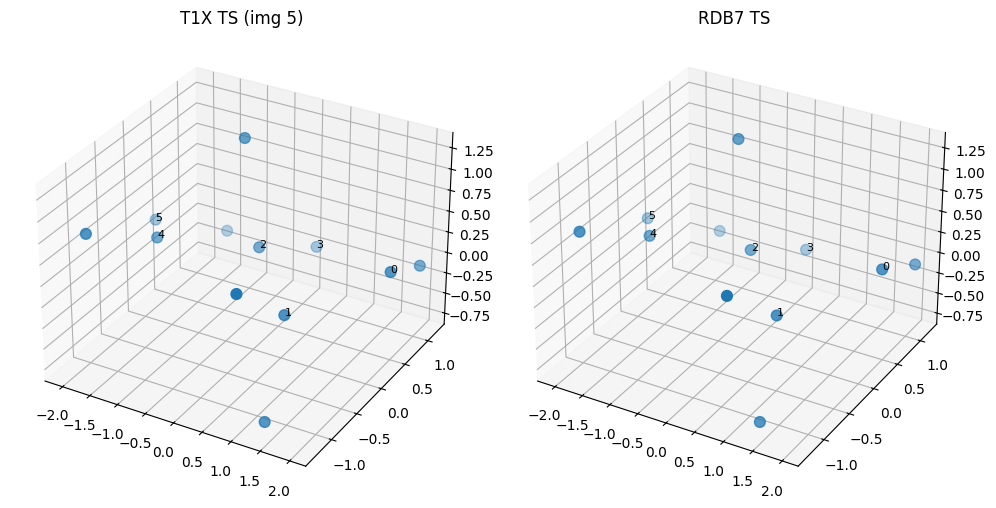

In [14]:
# Pick one and compare:
example_smiles = list(common_smiles)[1094]  # Or any index
result = compare_reaction_by_smiles(example_smiles, visualize=True, visualize_backend='nglview', align=True)

In [11]:

# ============================================================================
# BONUS: Visualize the full reaction pathway (multiple images)
# ============================================================================

def visualize_reaction_pathway(t1x_sample, dataset_name="T1X"):
    """
    Visualize the full reaction pathway (all images).
    
    Parameters:
    -----------
    t1x_sample : Data
        T1X sample with pos_N_3_I (N_atoms, 3, N_images)
    dataset_name : str
        Name of the dataset (for display)
    """
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    
    pos_N_3_I = t1x_sample.pos_N_3_I
    ts_idx = int(t1x_sample.ts_idx.item()) if hasattr(t1x_sample.ts_idx, 'item') else int(t1x_sample.ts_idx)
    
    n_atoms, _, n_images = pos_N_3_I.shape
    
    # Convert to numpy
    pos_np = pos_N_3_I.cpu().numpy() if hasattr(pos_N_3_I, 'cpu') else np.array(pos_N_3_I)
    
    # Create figure with subplots for first 5 images
    n_show = min(5, n_images)
    fig = plt.figure(figsize=(16, 3*n_show))
    
    for i in range(n_show):
        ax = fig.add_subplot(n_show, 1, i+1, projection='3d')
        
        coords = pos_np[:, :, i]
        ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], s=100, alpha=0.6)
        
        # Add atom labels
        for j in range(min(5, n_atoms)):  # Label first 5 atoms
            ax.text(coords[j, 0], coords[j, 1], coords[j, 2], f'A{j}', fontsize=8)
        
        # Highlight TS
        marker = "★ TS" if i == ts_idx else f"Image {i}"
        color = "red" if i == ts_idx else "blue"
        
        ax.set_title(f"{dataset_name} - {marker} ({n_images} images total)", 
                    fontsize=12, fontweight='bold', color=color)
        ax.set_xlabel('X (Å)')
        ax.set_ylabel('Y (Å)')
        ax.set_zlabel('Z (Å)')
    
    plt.tight_layout()
    plt.show()
    
    print(f"✓ Visualized {n_show} of {n_images} images from {dataset_name}")
    print(f"  TS index marked with ★ (image {ts_idx})")

# Example: visualize T1X pathway
print("\n" + "=" * 100)
print("PATHWAY VISUALIZATION EXAMPLE:")
print("=" * 100)
print("\nTo visualize the full reaction pathway for T1X (multiple images along NEB path):")
print("\n  visualize_reaction_pathway(t1x_sample, 'T1X')")
print("\nThis creates a matplotlib figure showing the first 5 images of the reaction path,")
print("with the transition state (TS) highlighted in red.")



PATHWAY VISUALIZATION EXAMPLE:

To visualize the full reaction pathway for T1X (multiple images along NEB path):

  visualize_reaction_pathway(t1x_sample, 'T1X')

This creates a matplotlib figure showing the first 5 images of the reaction path,
with the transition state (TS) highlighted in red.


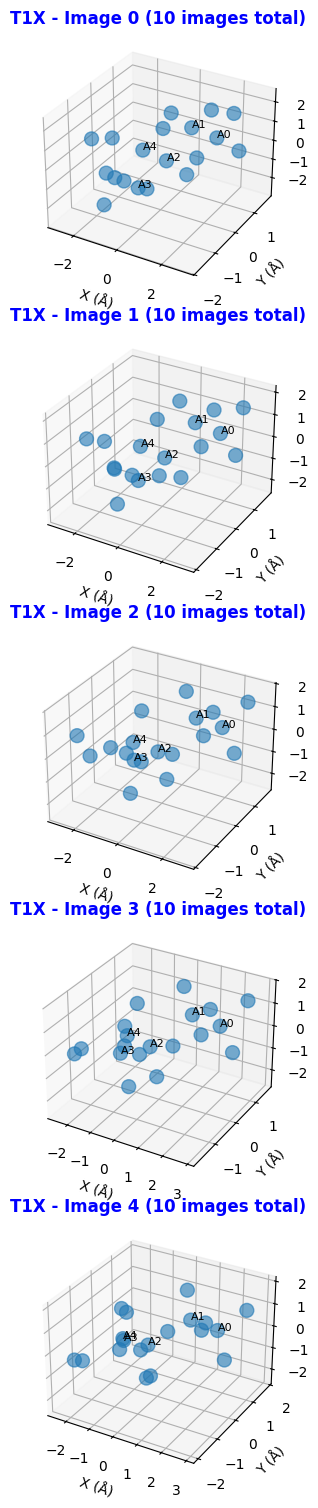

✓ Visualized 5 of 10 images from T1X
  TS index marked with ★ (image 6)


In [12]:
visualize_reaction_pathway(t1x_sample, 'T1X')